# 02 — Part 1 baseline, augmentation, and final ridge

The retained path is supervised LR → K-Means pseudo-label augmentation → locally calibrated RBF models → final fixed RBF ridge. The supervised baseline and K-Means have equal sample F1 under the same nonempty output rule. Their per-reason and exact-set errors differ.

All cells run safely with saved evidence. Optional training is disabled. `tools/src/` retains the actual training functions and experiment procedures; code cells below expose and call them explicitly.


In [2]:
from pathlib import Path
import sys, os, json, tempfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'models/selection.json').is_file() and (p/'tools/src').is_dir())
for module_dir in (ROOT/'tools/src', ROOT/'report/scripts'):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'midterm-report-mpl'))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code
from midterm_evaluation import REASONS, dataset_path
RUN_TRAINING = False  # Explicit opt-in only. Run All uses saved evidence and does not train.
print('Consolidated project | mode: saved evidence | training:', RUN_TRAINING)


In [3]:
from report_analysis import build_report
report=build_report(ROOT)
comparison=pd.read_csv(ROOT/'report/analysis/part1_validation_summary.csv')
display(comparison)
by_reason=pd.read_csv(ROOT/'report/analysis/part1_validation_by_reason.csv')
display(by_reason.pivot(index='reason',columns='model',values='f1').reindex(REASONS))


,model,threshold,gold_fit_rows,decision_policy,n_rows,f1_samples,f1_macro,n_empty_set_fallbacks,exact_sets,subset_accuracy
0,supervised_lr,0.50,157,threshold_then_argmax_if_empty,78,0.878205,0.698990,4,61,0.782051
1,initial_kmeans_lr,0.50,157,threshold_then_argmax_if_empty,78,0.854701,0.669045,3,62,0.794872
2,retained_kmeans_lr,0.35,157,threshold_then_argmax_if_empty,78,0.878205,0.764842,0,64,0.820513
3,fixed_ridge_157_gold,0.50,157,threshold_then_argmax_if_empty,78,0.893162,0.782910,7,65,0.833333


model,fixed_ridge_157_gold,initial_kmeans_lr,retained_kmeans_lr,supervised_lr
reason,,,,
Safety,0.941176,0.823529,0.842105,0.857143
Funding,0.666667,0.400000,0.666667,0.285714
Efficacy,0.800000,0.740741,0.838710,0.812500
Recruitment,0.980392,0.952381,0.943396,0.979592
Other,0.526316,0.428571,0.533333,0.560000


## Figure code: validation F1 by reason

All four validation variants fit 157 labeled training trials. Fixed ridge uses the saved historical validation fit from the later controlled comparison, not the 235-label submission fit. `initial_kmeans_lr` is retained in the table as an augmentation ablation. Historical GMM scores used an older empty-set policy and are not part of this fair table.


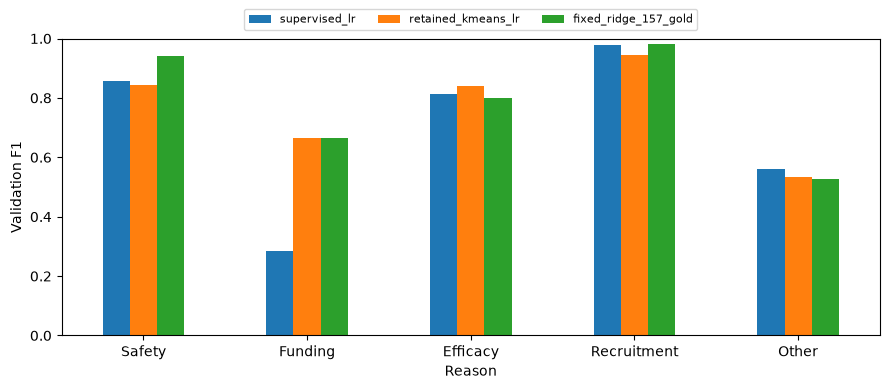

In [4]:
import matplotlib.pyplot as plt
shown=['supervised_lr','retained_kmeans_lr','fixed_ridge_157_gold']
matrix=by_reason.pivot(index='reason',columns='model',values='f1').reindex(REASONS)[shown]
ax=matrix.plot.bar(figsize=(9,4),ylim=(0,1),rot=0)
ax.set_ylabel('Validation F1'); ax.set_xlabel('Reason')
ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=3,fontsize=8)
ax.figure.tight_layout()
display(ax.figure); plt.close(ax.figure)


## Historical augmentation experiment and executable training specification

The next table is retained historical evidence with the original `allow empty set` rule. In particular, GMM's sample F1 of 0.6667 cannot be placed directly beside the fair argmax table as an identical-policy comparison. Its saved row probabilities were not retained, so this cleanup does not invent an argmax-adjusted GMM score.

The disabled code cell supplies the original supervised, K-Means and GMM training recipes using functions from `tools/src/`. It preserves observed labels and gives recovered labels weight 0.1. Running the notebook normally does not execute these fits or overwrite any evidence.


In [5]:
historical=pd.read_csv(ROOT/'models/part1/02_kmeans_lr/evidence/augmentation/validation_comparison.csv')
historical['decision_policy']='original threshold0.5; empty sets allowed'
display(historical)
display(pd.read_csv(ROOT/'models/part1/02_kmeans_lr/evidence/augmentation/validation_reason_comparison.csv'))


,model,run_id,n_rows,f1_samples,f1_macro,delta_f1_samples,delta_f1_macro,decision_policy
0,supervised_baseline,part1_supervised_lr_embeddings_seed42_v1,78,0.865385,0.706674,0.000000,0.000000,original threshold0.5; empty sets allowed
1,kmeans_augmented_lr,part1_kmeans_k10_lr_pseudo010_seed42_v1,78,0.820513,0.633167,-0.044872,-0.073506,original threshold0.5; empty sets allowed
2,gmm_augmented_lr,part1_gmm_k10_lr_pseudo010_seed42_v1,78,0.666667,0.448922,-0.198718,-0.257752,original threshold0.5; empty sets allowed


,model,reason,n_positive,n_negative,f1,precision,recall
0,supervised_baseline,Safety,9,69,0.857143,0.750000,1.000000
1,supervised_baseline,Funding,4,74,0.285714,0.333333,0.250000
2,supervised_baseline,Efficacy,14,64,0.827586,0.800000,0.857143
3,supervised_baseline,Recruitment,50,28,0.979592,1.000000,0.960000
4,supervised_baseline,Other,10,68,0.583333,0.500000,0.700000
5,kmeans_augmented_lr,Safety,9,69,0.823529,0.875000,0.777778
6,kmeans_augmented_lr,Funding,4,74,0.400000,1.000000,0.250000
7,kmeans_augmented_lr,Efficacy,14,64,0.692308,0.750000,0.642857
8,kmeans_augmented_lr,Recruitment,50,28,0.942308,0.907407,0.980000
9,kmeans_augmented_lr,Other,10,68,0.307692,0.666667,0.200000


In [6]:
if RUN_TRAINING:
    import midterm_part1_local_consensus as local
    from sklearn.cluster import KMeans
    from sklearn.mixture import GaussianMixture
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.multiclass import OneVsRestClassifier
    from threadpoolctl import threadpool_limits
    from midterm_augmentation import (observed_label_mask, cluster_memberships,
        estimate_cluster_reason_rates, recover_labels, fit_reason_classifiers,
        predict_reason_probabilities, logistic_parameters)
    from midterm_evaluation import evaluate_part1
    train=pd.read_csv(dataset_path(ROOT,'part1','train'))
    validation=pd.read_csv(dataset_path(ROOT,'part1','val'))
    labels=train[list(REASONS)].to_numpy(dtype=int)
    observed=observed_label_mask(labels)
    scaler=StandardScaler().fit(train[local.EMB])
    x=scaler.transform(train[local.EMB]);x_val=scaler.transform(validation[local.EMB])
    historical_refits=[]
    with threadpool_limits(limits=1):
        supervised=OneVsRestClassifier(LogisticRegression(**logistic_parameters(42)),n_jobs=1).fit(x[observed],labels[observed])
        p=supervised.predict_proba(x_val)
        score_frame=pd.DataFrame(p,columns=REASONS).assign(ID=validation.ID)
        historical_refits.append({'model':'supervised_lr',**evaluate_part1(validation,score_frame,.5).summary})
        clusterers={
          'kmeans':KMeans(n_clusters=10,n_init=20,max_iter=500,tol=1e-4,algorithm='lloyd',init='k-means++',random_state=42),
          'gmm':GaussianMixture(n_components=10,covariance_type='diag',n_init=5,max_iter=500,tol=1e-3,reg_covar=1e-4,init_params='kmeans',random_state=42)}
        for method,clusterer in clusterers.items():
            clusterer.fit(x)
            memberships=cluster_memberships(clusterer,x,method)
            mapping=estimate_cluster_reason_rates(memberships,labels,smoothing_strength=2.)
            recovered=recover_labels(labels,memberships,mapping,threshold=.5,pseudo_weight=.1)
            assert np.array_equal(recovered['labels'][observed],labels[observed])
            classifiers,_warnings=fit_reason_classifiers(x,recovered['labels'],recovered['sample_weight'],seed=42)
            p=predict_reason_probabilities(classifiers,x_val)
            score_frame=pd.DataFrame(p,columns=REASONS).assign(ID=validation.ID)
            historical_refits.append({'model':method+'_augmented_lr',**evaluate_part1(validation,score_frame,.5).summary})
    display(pd.DataFrame(historical_refits))
else:
    print('Historical baseline/K-Means/GMM training skipped; retained scores shown above.')


In [7]:
import inspect
import midterm_part1_local_consensus as local
from midterm_augmentation import estimate_cluster_reason_rates, recover_labels
display(Code(inspect.getsource(estimate_cluster_reason_rates)+inspect.getsource(recover_labels),language='python'))
display(Code(inspect.getsource(local.fit_base)+inspect.getsource(local.fit_calibrated),language='python'))
locked=json.loads((ROOT/'models/part1/03_kernel_ridge/evidence/selection_procedure/final_selection.json').read_text())
display({'fixed_ridge':locked['local_config'],'decision':locked['recipes']['final']})


def estimate_cluster_reason_rates(memberships, labels, smoothing_strength: float = 2.0):
    """Smooth visible-seed reason rates toward the visible-seed global prior.

    For cluster k and reason r:
      q[k,r] = (sum_i w[i,k]*y[i,r] + alpha*prior[r]) / (sum_i w[i,k] + alpha)
    Every sum over i uses only observed training seeds. A cluster with no observed
    membership mass falls back to the prior. These estimates are not calibrated
    population prevalences because the visible seeds were not sampled at random.
    """
    weights = membership_matrix(memberships)
    labels = np.asarray(labels, dtype=float)
    observed = observed_label_mask(labels)
    if len(weights) != len(labels):
        raise ValueError("Membership and label rows must align.")
    if not np.isfinite(smoothing_strength) or smoothing_strength <= 0:
        raise ValueError("Smoothing strength must be finite and positive.")
    prior = labels[observed].mean(axis=0)
    mass = weights[observed].sum(axis=0)
    positive_mass = weights[observed].T @ labels[observed]
    rates = (positive_mass + smoothing_strength * prior) / (mass[:, None] + smoothing_strength)
    return {"rates": rates, "global_prior": prior, "observed_membership_mass": mass,
            "positive_membership_mass": positive_mass, "smoothing_strength": float(smoothing_strength)}
def recover_labels(labels, memberships, mapping, *, threshold: float = 0.5, pseudo_weight: float = 0.1):
    """Fill every masked row, preserving observed labels exactly.

    Decision margins describe distance from the fixed decision boundary. They do
    not estimate label accuracy. Cluster assignment certainty has a separate meaning.
    """
    labels = np.asarray(labels, dtype=float)
    observed = observed_label_mask(labels)
    weights = membership_matrix(memberships)
    rates = np.asarray(mapping["rates"], dtype=float)
    if len(weights) != len(labels) or rates.shape != (weights.shape[1], 5):
        raise ValueError("Labels, memberships, and cluster rates have incompatible shapes.")
    if not np.isfinite(rates).all() or ((rates < 0) | (rates > 1)).any():
        raise ValueError("Reason rates must be finite values in [0, 1].")
    if not np.isfinite(threshold) or not 0 < threshold < 1:
        raise ValueError("The decision threshold must lie strictly between zero and one.")
    if not np.isfinite(pseudo_weight) or not 0 < pseudo_weight <= 1:
        raise ValueError("The pseudo-label weight must be in (0, 1].")
    scores = weights @ rates
    recovered = labels.copy().astype(int)
    recovered[~observed] = (scores[~observed] >= threshold).astype(int)
    # At threshold 0.5, the normalized margin equals 2*abs(score-0.5).
    margins = np.where(scores >= threshold, (scores-threshold)/(1-threshold), (threshold-scores)/threshold)
    entropy = -(weights * np.log(np.clip(weights, 1e-300, 1))).sum(axis=1)
    normalized_entropy = entropy / np.log(weights.shape[1]) if weights.shape[1] > 1 else np.zeros(len(weights))
    return {"labels": recovered, "observed": observed, "scores": scores,
            "sample_weight": np.where(observed, 1.0, pseudo_weight),
            "decision_margins": margins, "dominant_cluster": weights.argmax(axis=1),
            "max_membership": weights.max(axis=1), "normalized_membership_entropy": normalized_entropy}

def fit_base(scope, config):
    d = scope.data
    geom = Geometry.fit(d.x[scope.eligible], config["geometry"])
    z = geom.transform(d.x[scope.gold])
    y = d.y[scope.gold]
    family = config["family"]
    distances = pdist(z, "sqeuclidean")
    median = float(np.median(distances[distances > 1e-12])) if np.any(distances > 1e-12) else 1.
    gamma = config["bandwidth"] / median
    matrix = z if family == "linear" else np.exp(-gamma * cdist(z, z, "sqeuclidean"))
    if family == "ridge":
        coefficients = solve(matrix + config["strength"] * np.eye(len(z)), y, assume_a="pos")
        return BaseModel(geom, family, z, gamma, [], coefficients)
    estimators = []
    for j in range(5):
        if len(np.unique(y[:, j])) == 1:
            rate = (y[:, j].sum() + 1) / (len(y) + 2)
            estimators.append(float(np.log(rate / (1 - rate))))
            continue
        if family == "svm":
            model = SVC(C=config["strength"], kernel="precomputed", max_iter=20000, tol=1e-4)
        else:
            model = LogisticRegression(**{**logistic_parameters(42), "C": config["strength"]})
        model.fit(matrix, y[:, j])
        estimators.append(model)
    return BaseModel(geom, family, z, gamma, estimators, None)
def fit_calibrated(scope, config, seed):
    raw = np.full((len(scope.gold), 5), np.nan)
    members = []
    for held, inner in scope.folds(seed):
        m = fit_base(inner, config)
        raw[held] = m.raw(scope.data.x[scope.gold[held]])
        members.append(m)
    if not np.isfinite(raw).all():
        raise RuntimeError("Incomplete calibration cross-fit")
    return Calibrated(fit_base(scope, config), Sigmoid.fit(raw, scope.data.y[scope.gold]), members)

{'fixed_ridge': {'geometry': 'global',
  'family': 'ridge',
  'bandwidth': 0.5,
  'strength': 0.1},
 'decision': {'source': 'local', 'source_weight': 1.0, 'threshold': 0.5}}

## Reproduce saved submission decisions without training

The final ridge uses a single global scale, gamma = 0.5 / median nonzero squared training distance, ridge penalty 0.1, grouped cross-fit sigmoid calibration, and threshold 0.5 with argmax when no label passes. It uses 235 real labels, no consensus pseudo-labels and no fusion. Its saved file scored 0.88568 publicly.


In [8]:
import joblib
test=pd.read_csv(dataset_path(ROOT,'part1','test'))
saved_model=joblib.load(ROOT/'models/part1/03_kernel_ridge/model.joblib')
probabilities=saved_model.predict(test[local.EMB].to_numpy())
decisions=local.decide(probabilities,.5)
reproduced=[' '.join(reason for reason,bit in zip(REASONS,row) if bit) for row in decisions]
submission=pd.read_csv(ROOT/'models/part1/03_kernel_ridge/submission.csv').set_index('ID')
assert reproduced==submission.loc[test.ID,'Predicted'].tolist()
print('Exact saved submission decisions reproduced:',len(reproduced))


## Optional training (off by default)

The following cell reproduces the selected 235-label recipe only; it does not search settings or overwrite artifacts. Enabling it intentionally uses validation labels for the final fit, so its predictions on those rows are not independent validation evidence.


In [9]:
if RUN_TRAINING:
    from threadpoolctl import threadpool_limits
    data,test_frame=local.load_data(ROOT)
    scope=data.scope(data.gold,np.arange(len(data.frame)))
    with threadpool_limits(limits=1):
        reproduced_fit=local.fit_calibrated(scope,locked['local_config'],seed=942)
    np.testing.assert_allclose(reproduced_fit.predict(test_frame[local.EMB].to_numpy()),probabilities,atol=1e-12,rtol=0)
    print('Selected ridge refit verified; nothing overwritten.')
else:
    print('Optional selected-model training skipped.')


In [10]:
local_summary=json.loads((ROOT/'models/part1/03_kernel_ridge/evidence/selection_procedure/summary.json').read_text())
fixed_summary=json.loads((ROOT/'models/part1/exploration/local_followup/summary.json').read_text())
display(pd.DataFrame([
 {'estimate':'Earlier nested local selection procedure','OOF_sample_F1':local_summary['overall']['final']['sample_f1']},
 {'estimate':'Fixed ridge recipe, later grouped re-evaluation','OOF_sample_F1':fixed_summary['overall']['baseline']['sample_f1']}]))
print('The first score evaluates a selection procedure; it is not a separate unbiased estimate of the fixed ridge configuration.')


,estimate,OOF_sample_F1
0,Earlier nested local selection procedure,0.898345
1,"Fixed ridge recipe, later grouped re-evaluation",0.902600
